# DataCo Supply Chain Analysis

Data Science, Semester 3, Plaksha University (Assignment 1). Prasham Sheth (U20230026).

Exploratory analysis of the DataCo Smart Supply Chain dataset (180,519 orders, 53 columns). It covers data quality, sales and profit by customer segment, region and product category, customer lifetime value (CLV) and profit margins, and ends with a short business report.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)

data = pd.read_excel("data/DataCoSupplyChainDataset.xlsx")

## Question 1: Understanding the data

In [2]:
rows, columns = data.shape
print("Number of rows:", rows, "\nNumber of columns:", columns)
print("\nData types:")
print(data.dtypes.value_counts())
data.dtypes.to_frame("dtype").T

Number of rows: 180519 
Number of columns: 53

Data types:
object            22
float64           15
int64             14
datetime64[ns]     2
Name: count, dtype: int64


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
dtype,object,int64,int64,float64,float64,object,int64,int64,object,object,...,float64,int64,int64,float64,object,object,float64,int64,datetime64[ns],object


In [3]:
# Summary statistics for the main numerical fields
key_numeric = ["Days for shipping (real)", "Days for shipment (scheduled)", "Sales", "Order Item Quantity",
               "Order Item Discount Rate", "Order Profit Per Order", "Late_delivery_risk"]
data[key_numeric].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.50,1.62,0.00,2.00,3.00,5.00,6.00
Days for shipment (scheduled),180519.0,2.93,1.37,0.00,2.00,4.00,4.00,4.00
Sales,180519.0,203.77,132.27,9.99,119.98,199.92,299.95,1999.99
Order Item Quantity,180519.0,2.13,1.45,1.00,1.00,1.00,3.00,5.00
Order Item Discount Rate,180519.0,0.10,0.07,0.00,0.04,0.10,0.16,0.25
Order Profit Per Order,180519.0,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80
Late_delivery_risk,180519.0,0.55,0.50,0.00,0.00,1.00,1.00,1.00


In [4]:
# Frequency distributions for the main categorical variables
for col in ["Type", "Delivery Status", "Customer Segment", "Market", "Shipping Mode"]:
    print(data[col].value_counts().to_string(), "\n")
print("Distinct product categories:", data["Category Name"].nunique(), "| distinct order regions:", data["Order Region"].nunique())

Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616 

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754 

Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226 

Market
LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614 

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737 

Distinct product categories: 50 | distinct order regions: 23


In [5]:
missing = data.isnull().sum()
missing[missing > 0].to_frame("missing values")

,missing values
Customer Lname,8
Customer Zipcode,3
Order Zipcode,155679
Product Description,180519


**Insights**

- **Customer Lname** (8 missing) and **Customer Zipcode** (3 missing) are rarely empty. The last name is only needed for billing, warranty or refunds, so these few rows can be left as they are or the column dropped.
- **Order Zipcode** is missing for 86% of orders, so it is not usable for analysis.
- **Product Description** is completely empty and can be dropped.

## Question 2: Sales and profit by segment, region and category

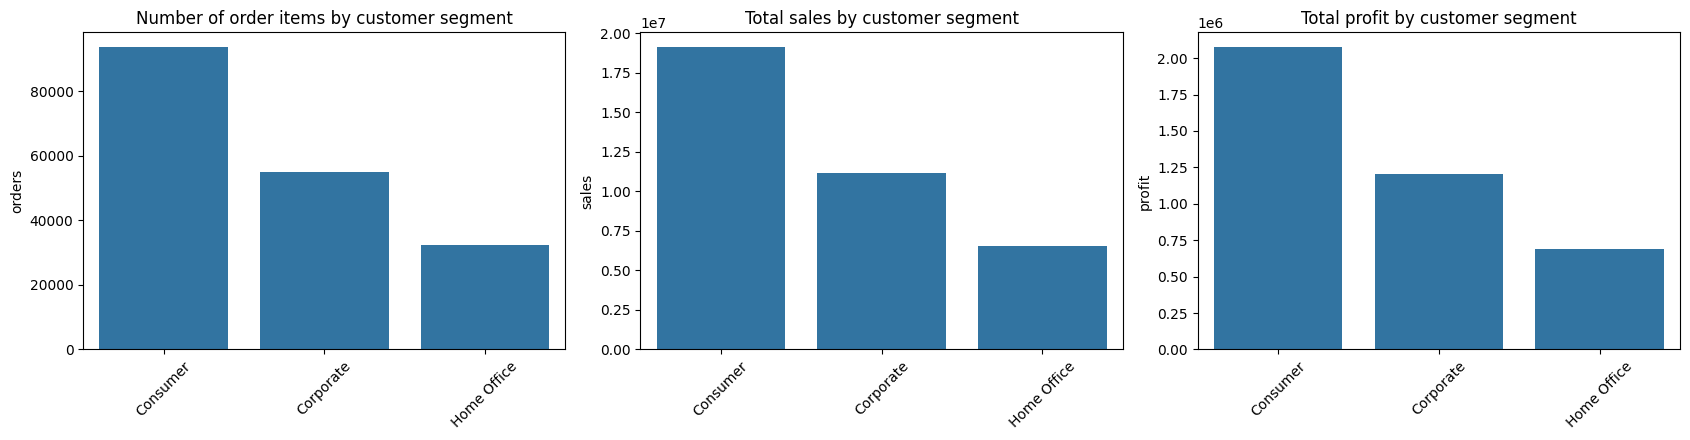

,orders,sales,profit,profit margin %
Customer Segment,,,,
Consumer,93504,19095790.2,2073487.7,10.9
Corporate,54789,11168406.8,1202575.0,10.8
Home Office,32226,6520538.0,690840.3,10.6


In [6]:
def bar_pair(group_col, title, rotate=45, fname=None):
    summary = data.groupby(group_col).agg(orders=("Order Id", "size"), sales=("Sales", "sum"),
                                          profit=("Order Profit Per Order", "sum")).sort_values("sales", ascending=False)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, col, label in zip(axes, ["orders", "sales", "profit"], ["Number of order items", "Total sales", "Total profit"]):
        sns.barplot(x=summary.index, y=summary[col], ax=ax, color="tab:blue")
        ax.set_title(f"{label} by {title}")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=rotate)
    plt.tight_layout()
    if fname:
        plt.savefig(fname)
    plt.show()
    summary["profit margin %"] = 100 * summary["profit"] / summary["sales"]
    return summary.round(1)

bar_pair("Customer Segment", "customer segment", fname="images/segments.png")

**Insights**

- The **Consumer** segment brings in the most orders, sales and profit. That is about half of the business.
- **Corporate** and **Home Office** follow. All three segments have almost the same profit margin (10.6-10.9%), so the difference is in volume rather than profitability.

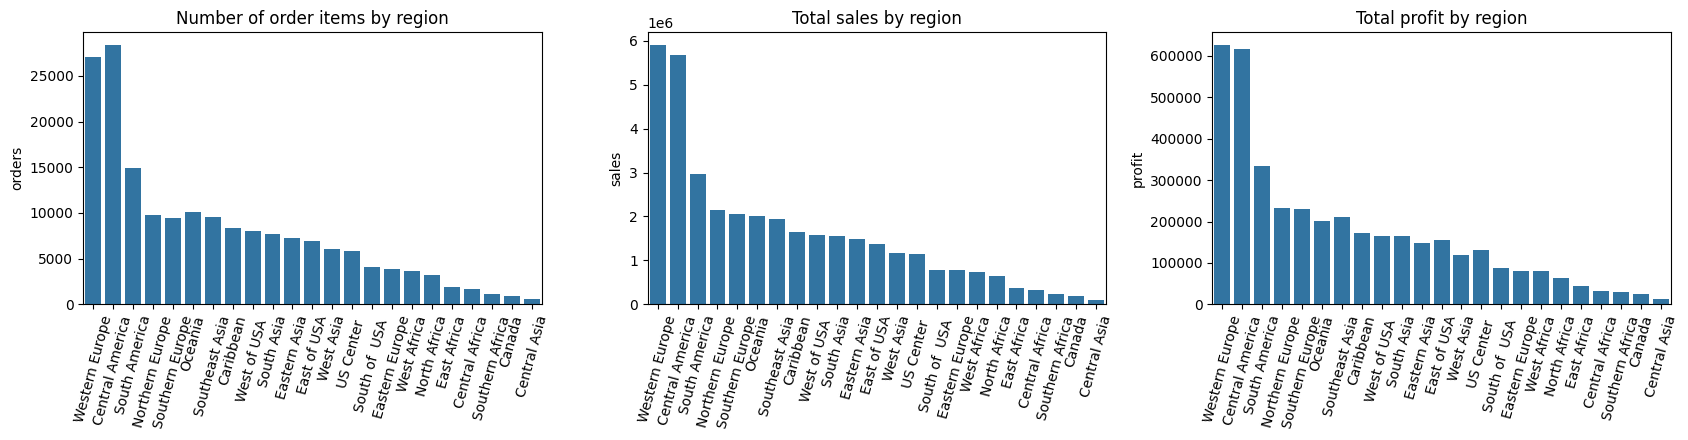

,orders,sales,profit,profit margin %
Order Region,,,,
Western Europe,27109,5894380.8,625446.1,10.6
Central America,28341,5665712.1,616341.6,10.9
South America,14935,2960881.4,335154.4,11.3
Northern Europe,9792,2155830.6,233450.6,10.8
Southern Europe,9431,2047918.8,230829.2,11.3
Oceania,10148,2016654.2,201478.0,10.0
Southeast Asia,9539,1932495.6,211342.8,10.9
Caribbean,8318,1651019.3,171825.6,10.4
West of USA,7993,1571416.0,164940.7,10.5


In [7]:
bar_pair("Order Region", "region", rotate=75, fname="images/regions.png")

**Insights**

- **Western Europe** and **Central America** have the most orders and the highest sales and profit.
- **Canada**, **Central Asia** and **Southern Africa** are the smallest markets, yet they have some of the highest margins (12-13.5%). That makes them attractive candidates for growth.

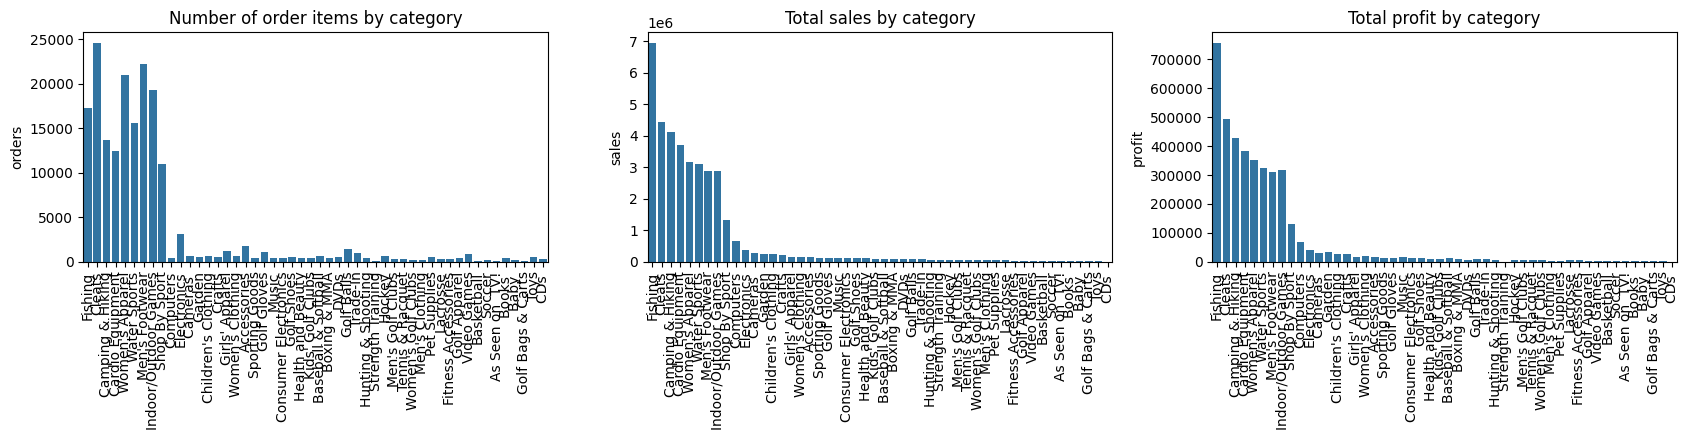

,orders,sales,profit,profit margin %
Category Name,,,,
Fishing,17325,6929653.7,756220.8,10.9
Cleats,24551,4431942.8,494636.9,11.2
Camping & Hiking,13729,4118425.6,427455.6,10.4
Cardio Equipment,12487,3694843.2,383011.1,10.4
Women's Apparel,21035,3147800.0,350421.0,11.1
Water Sports,15540,3113844.7,325147.0,10.4
Men's Footwear,22246,2891757.7,311902.8,10.8
Indoor/Outdoor Games,19298,2888993.9,318451.4,11.0
Shop By Sport,10984,1309522.0,129814.0,9.9


In [8]:
bar_pair("Category Name", "category", rotate=90, fname="images/categories.png").head(10)

**Insights**

- **Fishing** earns the most revenue and profit, even though **Cleats**, **Men's Footwear** and **Women's Apparel** have more orders. Each fishing order is worth much more.
- High-volume, low-value categories need many orders to make the same profit, so pricing or bundling could help them.

## Question 3: Customer lifetime value and profit margins

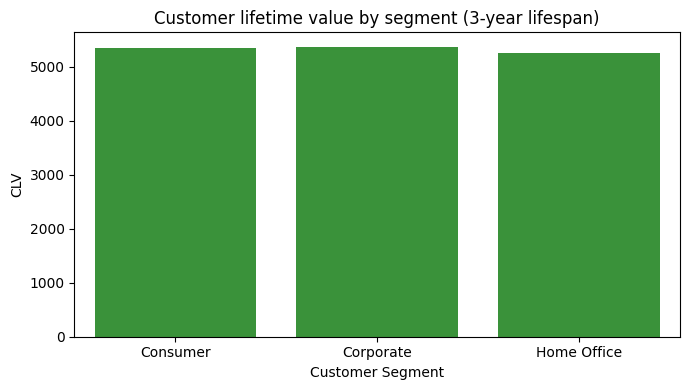

,sales,orders,customers,average purchase value,purchase frequency,CLV
Customer Segment,,,,,,
Consumer,19095790.16,34119,10695,559.68,3.19,5356.46
Corporate,11168406.84,19856,6239,562.47,3.18,5370.29
Home Office,6520538.02,11777,3718,553.67,3.17,5261.33


In [9]:
segment_data = data.groupby("Customer Segment").agg(sales=("Sales", "sum"), orders=("Order Id", "nunique"),
                                                    customers=("Customer Id", "nunique"))
segment_data["average purchase value"] = segment_data["sales"] / segment_data["orders"]
segment_data["purchase frequency"] = segment_data["orders"] / segment_data["customers"]
customer_lifespan = 3  # years, assumed equal for all segments
segment_data["CLV"] = segment_data["average purchase value"] * segment_data["purchase frequency"] * customer_lifespan

plt.figure(figsize=(7, 4))
sns.barplot(x=segment_data.index, y=segment_data["CLV"], color="tab:green")
plt.title("Customer lifetime value by segment (3-year lifespan)")
plt.ylabel("CLV")
plt.tight_layout()
plt.savefig("images/clv.png")
plt.show()
segment_data.round(2)

**Insights**

- CLV is about the same across segments, roughly 5,260 to 5,370 over three years. Customers in every segment order at a similar rate and spend a similar amount per order.
- Since value per customer barely differs, growth depends mostly on **acquiring more customers**, especially in the smaller Corporate and Home Office segments.

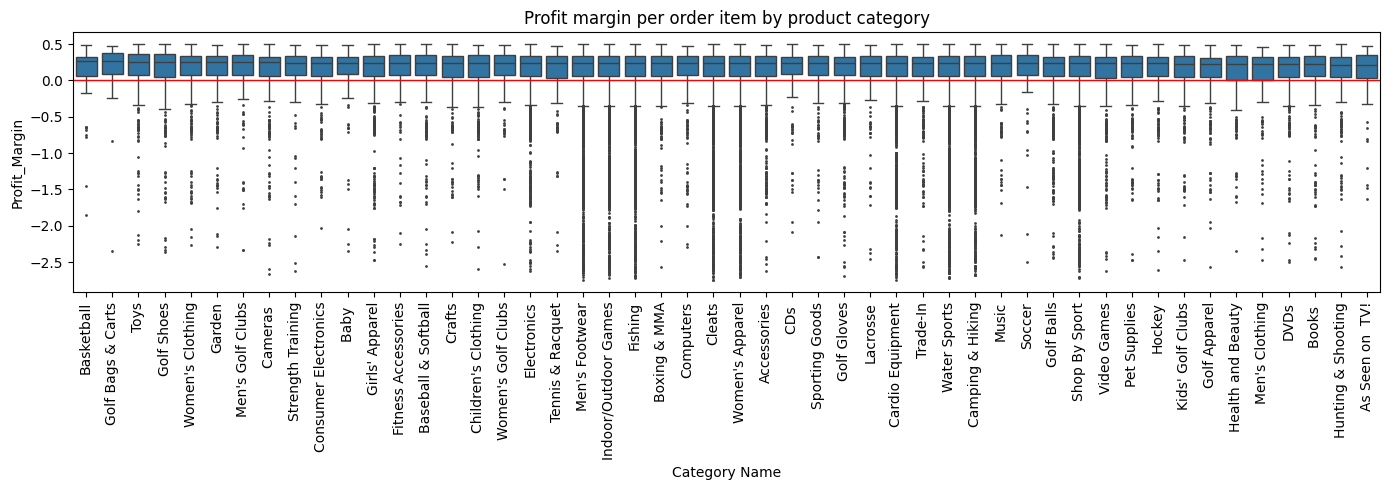

Order items sold at a loss: 18.7%


,median margin
Category Name,
Basketball,0.270
Golf Bags & Carts,0.262
Toys,0.259
Golf Shoes,0.252
Women's Clothing,0.251
Garden,0.250
Men's Golf Clubs,0.249
Cameras,0.248


In [10]:
data["Profit_Margin"] = data["Order Profit Per Order"] / data["Sales"]
order = data.groupby("Category Name")["Profit_Margin"].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 5))
sns.boxplot(x="Category Name", y="Profit_Margin", data=data, order=order, fliersize=1)
plt.axhline(0, color="red", lw=1)
plt.title("Profit margin per order item by product category")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("images/profit_margin.png")
plt.show()

loss_share = (data["Order Profit Per Order"] < 0).mean()
print(f"Order items sold at a loss: {loss_share:.1%}")
data.groupby("Category Name")["Profit_Margin"].median().sort_values(ascending=False).head(8).round(3).to_frame("median margin")

**Insights**

- The typical (median) order item earns a healthy margin, up to about 27% in the best categories. But every category has a long tail of loss-making orders, and about 19% of all order items lose money.
- The extreme negative outliers (heavy discounts or returns) should be investigated, because they wipe out the profit of many normal orders.

# DataCo Supply Chain Report

**1. Sales and profit by customer segment.** The Consumer segment produces about half of all sales and profit. Corporate and Home Office are smaller but equally profitable per sale (margin about 11%). *Recommendation:* keep Consumer customers with loyalty offers, and grow Corporate and Home Office through targeted business marketing.

**2. Sales and profit by region.** Western Europe and Central America lead in orders, sales and profit. Canada, Central Asia and Southern Africa are the smallest, but they have the highest margins. *Recommendation:* invest further in the leading regions, and treat the small high-margin regions as growth opportunities.

**3. Customer lifetime value.** CLV is almost the same in every segment (about 5,260-5,370 over three years). *Recommendation:* growth will come from adding customers rather than from changing how much existing customers spend.

**4. Profit margins by category.** Median margins are healthy, but about 19% of order items are sold at a loss, and every category has extreme loss outliers. *Recommendation:* review the discounting and return policies behind these orders, and prioritise high-value categories such as Fishing.